# Bitcoin price for tomorrow - JarvisTEC (`bitcoin`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Bitcoin Price Prediction (Kaggle, team-ai/bitcoin-price-prediction)](https://www.kaggle.com/datasets/team-ai/bitcoin-price-prediction), daily open, high, low and close prices of Bitcoin in USD from April 2013 to July 2017, plus a separate file with the following 7 days.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "bitcoin"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/bitcoin/bitcoin_price_Training - Training.csv"
# The 7 days that follow the training file (extra check, section 5).
TEST_PATH = "../../data/bitcoin/bitcoin_price_1week_Test - Test.csv"
TARGET_COLUMN = "close"  # daily closing price, USD
TASK_TYPE = "regression"  # "classification" or "regression"
IS_TIME_SERIES = True  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = "date"  # date column name when IS_TIME_SERIES is True
# Same-day values: unknown when tomorrow's close is forecast.
EXCLUDED_COLUMNS = ["open", "high", "low", "volume", "market_cap"]
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to forecast the **closing price of Bitcoin, in US dollars (USD), for the next day** from the closing prices of the previous days. Bitcoin is a decentralized digital currency (Nakamoto, 2008) whose price is set by supply and demand on exchanges and can change by several percent in a single day. A next-day estimate, together with an honest idea of how uncertain it is, is the answer expected from the command *"JarvisTEC, bitcoin price tomorrow"*.

- **Assumed user and cost of an error** (an assumption of this notebook, not something measured in the data): a person who follows the price out of curiosity or to decide whether to buy or sell a small amount the next day. A forecast that is too high could lead to buying before a fall, and one that is too low to selling before a rise; since the price can change by several percent in a day, a wrong forecast taken as a signal can cost money in either direction. Errors of both signs are therefore weighted equally (RMSE and MAE), and the answer is meant as a reference value, not as trading advice.
- **Task type:** time-series forecasting, framed as supervised regression with **lag features**: each row describes the days before the forecast day, and the target is that day's close. Only information known the day before is used.
- **Success metrics:** root mean squared error (**RMSE**) and mean absolute error (**MAE**) in USD, mean absolute percentage error (**MAPE**, comparable across periods because the price level changes a lot), the coefficient of determination (**R2**) and **directional accuracy** (how often the forecast gets the sign of the daily move right).
- **Baseline:** the naive forecast "tomorrow's close = today's close" (a random walk). It is the reference to beat: under the efficient-market hypothesis (Fama, 1970), past prices carry no exploitable information about the next price change, and Hyndman and Athanasopoulos (2021) recommend comparing every forecasting method with this simple benchmark. A model is useful only if it improves on it.
- **Support:** McNally, Roche and Caton (2018) address the same problem, predicting the price of Bitcoin with machine-learning methods, and are the closest reference for this notebook.

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (1556, 7)


,Date,Open,High,Low,Close,Volume,Market Cap
0,"Jul 31, 2017",2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000"
1,"Jul 30, 2017",2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000"
2,"Jul 29, 2017",2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000"
3,"Jul 28, 2017",2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000"
4,"Jul 27, 2017",2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000"


In [3]:
# snake_case names, real dates, numeric volume / market cap, and rows sorted
# from the oldest to the newest day (the file is newest-first).
def load_prices(path):
    prices = pd.read_csv(path)
    prices.columns = [
        c.strip().lower().replace(" ", "_") for c in prices.columns
    ]
    prices[DATE_COLUMN] = pd.to_datetime(
        prices[DATE_COLUMN], format="%b %d, %Y"
    )
    for column in ["volume", "market_cap"]:
        # Text with thousands separators; "-" marks a missing value.
        prices[column] = pd.to_numeric(
            prices[column].astype(str).str.replace(",", ""), errors="coerce"
        )
    return prices.sort_values(DATE_COLUMN).reset_index(drop=True)


df = load_prices(DATA_PATH)
kaggle_week = load_prices(TEST_PATH)
display(df.head())
display(df.tail(3))
print("Training file:", df[DATE_COLUMN].min().date(), "to",
      df[DATE_COLUMN].max().date(), "-", len(df), "days")
print("7-day file:", kaggle_week[DATE_COLUMN].min().date(), "to",
      kaggle_week[DATE_COLUMN].max().date(), "-", len(kaggle_week), "days")

,date,open,high,low,close,volume,market_cap
0,2013-04-28,135.30,135.98,132.10,134.21,NaN,1500520000
1,2013-04-29,134.44,147.49,134.00,144.54,NaN,1491160000
2,2013-04-30,144.00,146.93,134.05,139.00,NaN,1597780000
3,2013-05-01,139.00,139.89,107.72,116.99,NaN,1542820000
4,2013-05-02,116.38,125.60,92.28,105.21,NaN,1292190000


,date,open,high,low,close,volume,market_cap
1553,2017-07-29,2807.02,2808.76,2692.80,2726.45,803746000.0,46246700000
1554,2017-07-30,2724.39,2758.53,2644.85,2757.18,705943000.0,44890700000
1555,2017-07-31,2763.24,2889.62,2720.61,2875.34,860575000.0,45535800000


Training file: 2013-04-28 to 2017-07-31 - 1556 days
7-day file: 2017-08-01 to 2017-08-07 - 7 days


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
date,datetime64[us],0,0.00,1556
open,float64,0,0.00,1529
high,float64,0,0.00,1527
low,float64,0,0.00,1539
close,float64,0,0.00,1529
volume,float64,243,15.62,1313
market_cap,int64,0,0.00,1552


Duplicated rows: 0


,count,mean,min,25%,50%,75%,max,std
date,1556,2015-06-14 12:00:00,2013-04-28 00:00:00,2014-05-21 18:00:00,2015-06-14 12:00:00,2016-07-07 06:00:00,2017-07-31 00:00:00,NaN
open,1556.0,582.625328,68.5,254.2875,438.6,662.4375,2953.22,523.137312
high,1556.0,597.992847,74.56,260.3275,447.56,674.525,2999.91,542.992855
low,1556.0,567.851446,65.53,248.835,430.57,646.735,2840.53,505.877401
close,1556.0,584.239396,68.43,254.32,438.855,663.4025,2958.11,525.904442
volume,1313.0,148164250.281797,2857830.0,20710700.0,45301400.0,90378800.0,2569530000.0,324298655.46006
market_cap,1556.0,8694352847.686375,779255000.0,3598355000.0,6386210000.0,9898830000.0,48391200000.0,8707287539.008268


In [5]:
# Time-series quality checks.
steps = df[DATE_COLUMN].diff().dropna().dt.days
print("Calendar gaps (days between rows != 1):", int((steps != 1).sum()))
print("Duplicated dates:", int(df[DATE_COLUMN].duplicated().sum()))
print("First day with volume:",
      df.loc[df["volume"].notna(), DATE_COLUMN].min().date())
print("Days without volume:", int(df["volume"].isna().sum()))
inconsistent = (
    (df["low"] > df[["open", "close"]].min(axis=1))
    | (df["high"] < df[["open", "close"]].max(axis=1))
)
print("Rows where low/high do not bound open/close:", int(inconsistent.sum()))
print("Non-positive closes:", int((df["close"] <= 0).sum()))
gap = (df["open"] / df["close"].shift(1) - 1).abs()
print("Median |open / previous close - 1|:", round(gap.median() * 100, 3),
      "%")
print("Close: min", df["close"].min(), "on",
      df.loc[df["close"].idxmin(), DATE_COLUMN].date(),
      "| max", df["close"].max(), "on",
      df.loc[df["close"].idxmax(), DATE_COLUMN].date())

Calendar gaps (days between rows != 1): 0
Duplicated dates: 0
First day with volume: 2013-12-27
Days without volume: 243
Rows where low/high do not bound open/close: 0
Non-positive closes: 0
Median |open / previous close - 1|: 0.063 %
Close: min 68.43 on 2013-07-05 | max 2958.11 on 2017-06-11


**Data description.** Daily Bitcoin market data. The training file has **1556 consecutive days**, from 2013-04-28 to 2017-07-31, and 7 columns. A second file has the next 7 days (2017-08-01 to 2017-08-07) and is used only as an extra check in section 5.

| Variable | Meaning | Type / unit |
|---|---|---|
| `date` | day of the observation | date, daily |
| `open` | first price of the day | USD |
| `high` | highest price of the day | USD |
| `low` | lowest price of the day | USD |
| `close` | last price of the day (**target**, one day ahead) | USD |
| `volume` | amount traded during the day | USD (assumed; the file does not state the unit) |
| `market_cap` | market capitalization (price times coins in circulation) | USD |

**Data quality:**
- **Format:** the dates are text (`"Jul 31, 2017"`) and the rows are ordered from the newest to the oldest day; `volume` and `market_cap` are text with thousands separators. All of them are parsed, and the rows are sorted from the oldest to the newest day, as a time series requires.
- **Missing values:** `volume` is missing (`-`) on 243 days (15.62 %), all of them before 2013-12-27. No other column has missing values.
- **Continuity:** there are no calendar gaps and no duplicated dates. The file has a row for every day, weekends included, so every row is exactly one day after the previous one and "lag 1" always means "yesterday".
- **Consistency:** in every row the low and the high bound the open and the close, and there are no non-positive prices. The open is practically equal to the previous close (median difference 0.063 %), as expected in a market that does not close.
- **Range:** the close goes from 68.43 USD (2013-07-05) to 2958.11 USD (2017-06-11); the last close is 21.4 times the first one.
- **Columns not used as inputs:** the `open`, `high`, `low`, `volume` and `market_cap` of the forecast day are not known until that day ends, so using them would be leakage. The model is built only on past closes, which also lets the backend forecast from a short list of recent prices.

## 3. Data exploration

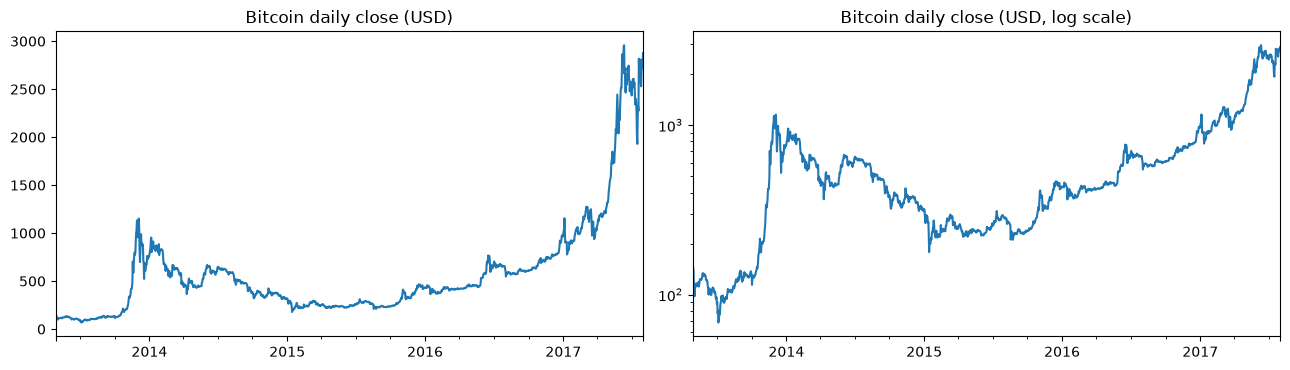

,days,first,last,min,max,change %
date,,,,,,
2013,248,134.21,754.01,68.43,1151.17,461.81
2014,365,771.40,320.19,310.74,953.29,-58.49
2015,365,314.25,430.57,178.10,465.32,37.02
2016,366,434.33,963.74,364.33,975.92,121.89
2017,212,998.33,2875.34,777.76,2958.11,188.01


Last / first close: 21.4


In [6]:
# Price over time, in linear and logarithmic scale.
target = TARGET_COLUMN
series = df.set_index(DATE_COLUMN)[target]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
series.plot(ax=axes[0])
axes[0].set_title("Bitcoin daily close (USD)")
series.plot(ax=axes[1], logy=True)
axes[1].set_title("Bitcoin daily close (USD, log scale)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

yearly = pd.DataFrame({
    "days": series.groupby(series.index.year).size(),
    "first": series.groupby(series.index.year).first(),
    "last": series.groupby(series.index.year).last(),
    "min": series.groupby(series.index.year).min(),
    "max": series.groupby(series.index.year).max(),
})
yearly["change %"] = (yearly["last"] / yearly["first"] - 1) * 100
display(yearly.round(2))
print("Last / first close:", round(series.iloc[-1] / series.iloc[0], 1))

In [7]:
# Same-day columns against the close: they move together, and none of them
# is known before the day ends.
corr = df[["close", "open", "high", "low", "volume", "market_cap"]].corr()
display(corr["close"].drop("close").rename("correlation with close").round(4))
print("Correlation close(t) vs. close(t-1):",
      round(series.autocorr(1), 5))

open          0.9975
high          0.9986
low           0.9988
volume        0.8865
market_cap    0.9930
Name: correlation with close, dtype: float64

Correlation close(t) vs. close(t-1): 0.9975


days                 1555.0000
mean                    0.0020
median                  0.0019
std                     0.0426
min                    -0.2662
max                     0.3575
skewness               -0.2346
excess kurtosis        10.3113
share of up days        0.5447
share |r| > 3 std       0.0212
mean |r|                0.0259
Name: daily log return, dtype: float64

Worst day: 2013-12-18 -0.2662 | best day: 2013-11-18 0.3575


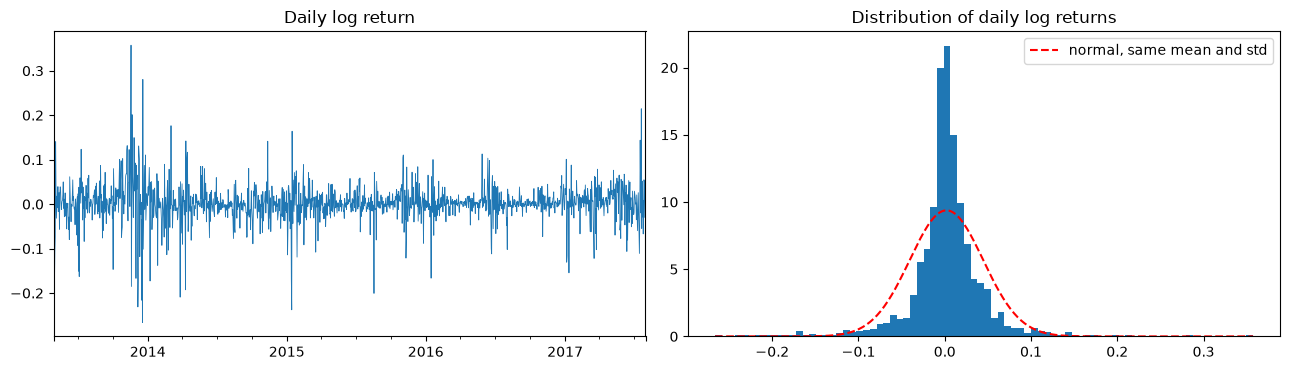

In [8]:
# Daily log returns: r_t = log(close_t / close_{t-1}).
returns = np.log(series).diff().dropna()
stats = {
    "days": len(returns),
    "mean": returns.mean(),
    "median": returns.median(),
    "std": returns.std(),
    "min": returns.min(),
    "max": returns.max(),
    "skewness": returns.skew(),
    "excess kurtosis": returns.kurt(),
    "share of up days": (returns > 0).mean(),
    "share |r| > 3 std": (returns.abs() > 3 * returns.std()).mean(),
    "mean |r|": returns.abs().mean(),
}
display(pd.Series(stats, name="daily log return").round(4))
print("Worst day:", returns.idxmin().date(), round(returns.min(), 4),
      "| best day:", returns.idxmax().date(), round(returns.max(), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
returns.plot(ax=axes[0], lw=0.6)
axes[0].set_title("Daily log return")
axes[0].set_xlabel("")
axes[1].hist(returns, bins=80, density=True)
grid = np.linspace(returns.min(), returns.max(), 300)
normal = np.exp(-0.5 * ((grid - returns.mean()) / returns.std()) ** 2)
normal /= returns.std() * np.sqrt(2 * np.pi)
axes[1].plot(grid, normal, "r--", label="normal, same mean and std")
axes[1].set_title("Distribution of daily log returns")
axes[1].legend()
plt.tight_layout()
plt.show()

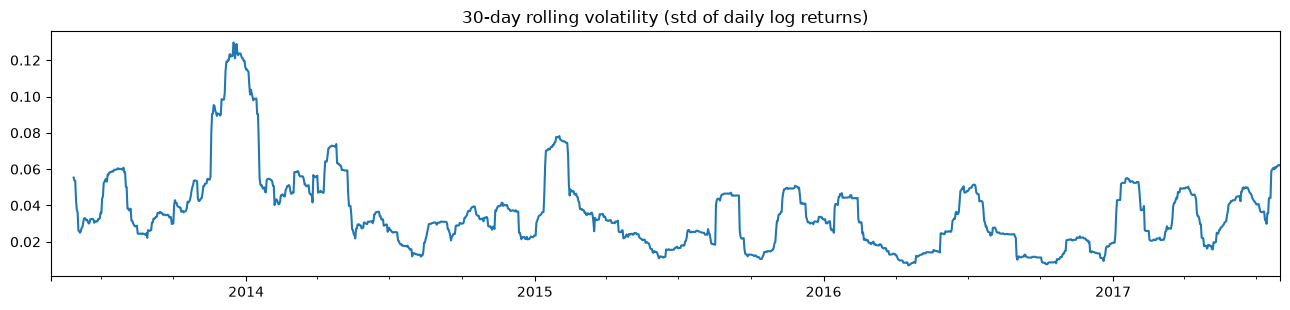

,count,mean,std,min,max
date,,,,,
2013,247,0.0070,0.0672,-0.2662,0.3575
2014,365,-0.0023,0.0394,-0.2091,0.1764
2015,365,0.0008,0.0368,-0.2376,0.1640
2016,366,0.0022,0.0252,-0.1664,0.1129
2017,212,0.0052,0.0435,-0.1545,0.2146


30-day volatility: min 0.0071 | median 0.0313 | max 0.1298


In [9]:
# Volatility: rolling 30-day standard deviation of the returns.
volatility = returns.rolling(30).std()
fig, ax = plt.subplots(figsize=(13, 3.2))
volatility.plot(ax=ax)
ax.set_title("30-day rolling volatility (std of daily log returns)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
by_year = returns.groupby(returns.index.year).agg(
    ["count", "mean", "std", "min", "max"]
)
display(by_year.round(4))
print("30-day volatility: min", round(volatility.min(), 4), "| median",
      round(volatility.median(), 4), "| max", round(volatility.max(), 4))

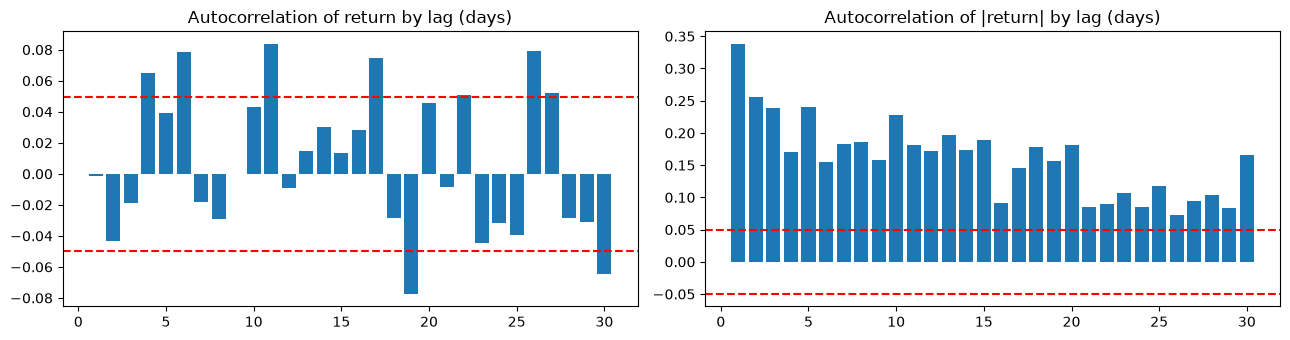

,price,return,|return|
1,0.9975,-0.0011,0.3383
2,0.9951,-0.0435,0.2564
3,0.9929,-0.0190,0.2383
4,0.9907,0.0648,0.1709
5,0.9885,0.0394,0.2403
6,0.9862,0.0786,0.1552
7,0.9840,-0.0184,0.1831


95 % band for white noise: +/- 0.0497
Return lags outside the band: [4, 6, 11, 17, 19, 22, 26, 27, 30]


,count,mean,std,t,up share
date,,,,,
0,223,0.0081,0.0455,2.6684,0.5785
1,222,0.0038,0.0414,1.3773,0.5676
2,222,-0.0028,0.0479,-0.8863,0.4910
3,222,0.0021,0.0495,0.6318,0.5315
4,222,-0.0005,0.0425,-0.1906,0.5676
5,222,0.0015,0.0352,0.6312,0.5541
6,222,0.0016,0.0328,0.7310,0.5225


In [10]:
# Autocorrelation: does yesterday say anything about today?
LAGS = range(1, 31)
acf = pd.DataFrame({
    "price": [series.autocorr(lag) for lag in LAGS],
    "return": [returns.autocorr(lag) for lag in LAGS],
    "|return|": [returns.abs().autocorr(lag) for lag in LAGS],
}, index=LAGS)
bound = 1.96 / np.sqrt(len(returns))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, column in zip(axes, ["return", "|return|"]):
    ax.bar(acf.index, acf[column])
    ax.axhline(bound, color="r", ls="--")
    ax.axhline(-bound, color="r", ls="--")
    ax.set_title(f"Autocorrelation of {column} by lag (days)")
plt.tight_layout()
plt.show()
display(acf.head(7).round(4))
print("95 % band for white noise: +/-", round(bound, 4))
print("Return lags outside the band:",
      acf.index[acf["return"].abs() > bound].tolist())

# Calendar effect: mean return by day of the week (0 = Monday).
weekday = returns.groupby(returns.index.dayofweek).agg(
    ["count", "mean", "std"]
)
weekday["t"] = weekday["mean"] / (weekday["std"] / np.sqrt(weekday["count"]))
weekday["up share"] = (returns > 0).groupby(returns.index.dayofweek).mean()
display(weekday.round(4))

**Exploration findings:**

- **The price is not stationary.** It has no stable level: 2013 ended at 754 USD after a maximum of 1151 USD, 2014 lost 58.5 %, 2016 gained 121.9 % and the first seven months of 2017 gained 188.0 %. The moves of 2017 (from 998 to 2875 USD) are much larger in USD than those of 2013 (from 134 to 754 USD), although the relative gain was larger in 2013 (461.8 % from late April against 188.0 %). Price changes scale with the price level, which is why the series is also plotted on a log scale and analyzed through returns.
- **Yesterday's price almost equals today's.** The correlation between the close and the previous close is 0.9975, and the same-day columns (`open`, `high`, `low`, `market_cap`) correlate above 0.99 with the close. This is why the naive forecast is so strong, and why a high R2 on the price level means very little here.
- **Returns are the informative quantity.** The daily log return has a mean of 0.0020 (0.2 % per day) and a standard deviation of 0.0426. The typical daily move (mean absolute return 0.0259) is more than ten times the average drift. Only 54.5 % of the days close higher than the day before.
- **Heavy tails:** the excess kurtosis is 10.3, and 2.12 % of the days move by more than 3 standard deviations (a normal distribution would give about 0.27 %). The extremes are -0.266 (2013-12-18) and +0.358 (2013-11-18). Large errors on a few days are therefore unavoidable, and they weigh heavily on RMSE.
- **Volatility changes over time and clusters.** The 30-day volatility ranges from 0.0071 to 0.1298 (median 0.0313). By year, the standard deviation of the returns goes from 0.0672 in 2013 down to 0.0252 in 2016 and back up to 0.0435 in 2017. The autocorrelation of the *absolute* returns is high and fades slowly (0.34 at lag 1, 0.18 at lag 7): calm days tend to follow calm days, and turbulent days tend to follow turbulent days.
- **The direction is almost unpredictable.** The autocorrelation of the returns themselves is practically zero at lag 1 (-0.0011) and small at the first seven lags: the largest is 0.079 (lag 6), and only lags 4 and 6 are outside the 95 % white-noise band (+/-0.0497). Over the 30 lags examined, 9 are outside the band, so the returns are not exactly white noise, but the dependence is weak. Past returns say something about how *large* the next move may be, but very little about its *sign*.
- **Calendar effect:** Monday has the highest mean return (0.0081, t = 2.67) and Wednesday the lowest (-0.0028); for the other days the mean return is not distinguishable from zero. With seven comparisons, one value of this size can appear by chance, so the day of the week is offered to the model as a weak candidate feature, not as an established effect.

**Preprocessing decisions:** parse and sort the dates; forecast the **daily log return** and convert it back to a price (the alternative, modelling the price level, is compared in section 4); build every feature from the 31 previous closes only (7 lagged returns, the mean and standard deviation of the returns over 7 and 30 days, the log distance of the last close to its 7- and 30-day moving averages, and the day of the week of the forecast day); remove no rows as outliers, because the extreme days are real and are part of what the forecast has to cope with.

## 4. Model

Two baselines and several models are compared with cross-validation, and the best model is chosen. Not all the preprocessing is inside the `Pipeline`. The lag and return features are computed outside it by one function, `build_features`, which is implemented identically in this notebook and in the backend adapter (`backend/models/bitcoin/adapter.py`). The conversion of the predicted log return back to a price (last close times the exponential of the return) is also done outside the `Pipeline`, in the same way in both places. Only the scaling of the numeric features and the one-hot encoding of the day of the week are inside the `Pipeline`, so they are fitted on the training part of each fold only. The features use only the closes before the forecast day, so nothing from that day leaks into its forecast. Only the selected model is tuned afterwards.

> **Time series:** because `IS_TIME_SERIES = True`, the split is chronological (the test set is the most recent data) and cross-validation uses `TimeSeriesSplit`. The temporal order is never shuffled.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- Lag features -------------------------------------------------------
# This function is re-implemented identically in
# backend/models/bitcoin/adapter.py (the backend never imports training/).
N_LAGS = 7
WINDOWS = (7, 30)
HISTORY_DAYS = 31  # closes needed: 30 returns for the longest window


def build_features(closes, forecast_date):
    """Features to forecast the close of ``forecast_date``.

    ``closes`` are the daily closes known the day before, oldest first.
    Nothing from the forecast day itself is used.
    """
    closes = np.asarray(closes, dtype=float)[-HISTORY_DAYS:]
    if len(closes) < HISTORY_DAYS or not (closes > 0).all():
        raise ValueError(f"{HISTORY_DAYS} positive closes are required")
    returns = np.diff(np.log(closes))
    features = {}
    for lag in range(1, N_LAGS + 1):
        features[f"close_lag_{lag}"] = float(closes[-lag])
    for lag in range(1, N_LAGS + 1):
        features[f"return_lag_{lag}"] = float(returns[-lag])
    for window in WINDOWS:
        features[f"return_mean_{window}"] = float(returns[-window:].mean())
        features[f"return_std_{window}"] = float(returns[-window:].std())
        features[f"gap_sma_{window}"] = float(
            np.log(closes[-1] / closes[-window:].mean())
        )
    features["day_of_week"] = int(forecast_date.weekday())
    return features


def make_dataset(prices):
    """One row per forecast day: features from the previous 31 closes."""
    closes = prices[TARGET_COLUMN].to_numpy()
    dates = prices[DATE_COLUMN]
    rows = []
    for i in range(HISTORY_DAYS, len(prices)):
        row = build_features(closes[i - HISTORY_DAYS:i], dates.iloc[i])
        row[DATE_COLUMN] = dates.iloc[i]
        row[TARGET_COLUMN] = closes[i]
        rows.append(row)
    return pd.DataFrame(rows).set_index(DATE_COLUMN)


data = make_dataset(df)
X = data.drop(columns=TARGET_COLUMN)
y = data[TARGET_COLUMN]
LEVEL_FEATURES = [f"close_lag_{lag}" for lag in range(1, N_LAGS + 1)]
RETURN_FEATURES = [c for c in X.columns if c not in LEVEL_FEATURES]

# ---- Chronological split: the test set is the most recent 20 % ----------
cut = int(len(X) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]
cv = TimeSeriesSplit(n_splits=5)

print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Train days:", X_train.index.min().date(), "to",
      X_train.index.max().date(), "| close", y_train.min(), "-",
      y_train.max())
print("Test days: ", X_test.index.min().date(), "to",
      X_test.index.max().date(), "| close", y_test.min(), "-", y_test.max())
print("Level features:", LEVEL_FEATURES)
print("Return features:", RETURN_FEATURES)
display(data.tail(3).round(4))

Train: (1220, 21)  Test: (305, 21)
Train days: 2013-05-29 to 2016-09-29 | close 68.43 - 1151.17
Test days:  2016-09-30 to 2017-07-31 | close 609.74 - 2958.11
Level features: ['close_lag_1', 'close_lag_2', 'close_lag_3', 'close_lag_4', 'close_lag_5', 'close_lag_6', 'close_lag_7']
Return features: ['return_lag_1', 'return_lag_2', 'return_lag_3', 'return_lag_4', 'return_lag_5', 'return_lag_6', 'return_lag_7', 'return_mean_7', 'return_std_7', 'gap_sma_7', 'return_mean_30', 'return_std_30', 'gap_sma_30', 'day_of_week']


,close_lag_1,close_lag_2,close_lag_3,close_lag_4,close_lag_5,close_lag_6,close_lag_7,return_lag_1,return_lag_2,return_lag_3,...,return_lag_6,return_lag_7,return_mean_7,return_std_7,gap_sma_7,return_mean_30,return_std_30,gap_sma_30,day_of_week,close
date,,,,,,,,,,,,,,,,,,,,,
2017-07-29,2809.01,2671.78,2529.45,2576.48,2754.86,2730.40,2810.12,0.0501,0.0547,-0.0184,...,-0.0288,0.0520,0.0074,0.0440,0.0405,0.0029,0.0609,0.1197,5,2726.45
2017-07-30,2726.45,2809.01,2671.78,2529.45,2576.48,2754.86,2730.40,-0.0298,0.0501,0.0547,...,0.0089,-0.0288,-0.0043,0.0414,0.0151,0.0024,0.0611,0.0874,6,2757.18
2017-07-31,2757.18,2726.45,2809.01,2671.78,2529.45,2576.48,2754.86,0.0112,-0.0298,0.0501,...,-0.0669,0.0089,0.0014,0.0404,0.0249,0.0035,0.0610,0.0949,0,2875.34


In [12]:
from sklearn import metrics
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge


def make_pipeline(estimator, columns, scale=True):
    """Select the model's columns, scale them and fit the estimator."""
    numeric = [c for c in columns if c != "day_of_week"]
    steps = [("num", StandardScaler() if scale else "passthrough", numeric)]
    if "day_of_week" in columns:
        steps.append((
            "dow",
            OneHotEncoder(categories=[list(range(7))]),
            ["day_of_week"],
        ))
    return Pipeline([
        ("prep", ColumnTransformer(steps)), ("model", estimator),
    ])


def fit_model(pipeline, kind, X_part, y_part):
    """``kind`` is what the pipeline predicts: "log_return" or "price"."""
    if kind == "log_return":
        return pipeline.fit(X_part, np.log(y_part / X_part["close_lag_1"]))
    return pipeline.fit(X_part, y_part)


def predict_price(pipeline, kind, X_part):
    """Next-day close in USD, whatever the pipeline predicts."""
    output = pipeline.predict(X_part)
    if kind == "log_return":
        output = X_part["close_lag_1"].to_numpy() * np.exp(output)
    return pd.Series(output, index=X_part.index)


def price_metrics(actual, predicted, last_close):
    moved = actual != last_close
    same_direction = (
        np.sign(predicted - last_close) == np.sign(actual - last_close)
    )
    # Undefined for a forecast that never predicts a move (the naive one).
    direction = (
        float(same_direction[moved].mean())
        if (predicted != last_close).any() else float("nan")
    )
    return {
        "rmse": metrics.mean_squared_error(actual, predicted) ** 0.5,
        "mae": metrics.mean_absolute_error(actual, predicted),
        "mape": float((np.abs(actual - predicted) / actual).mean() * 100),
        "r2": metrics.r2_score(actual, predicted),
        "directional_accuracy": direction,
    }


NAIVE = "Naive (tomorrow = today)"
BASELINES = [NAIVE, "Drift (mean return)"]
# name -> (pipeline, what it predicts)
candidates = {
    NAIVE: (
        make_pipeline(
            DummyRegressor(strategy="constant", constant=0.0),
            RETURN_FEATURES,
        ),
        "log_return",
    ),
    "Drift (mean return)": (
        make_pipeline(DummyRegressor(strategy="mean"), RETURN_FEATURES),
        "log_return",
    ),
    "Linear regression on price lags": (
        make_pipeline(LinearRegression(), LEVEL_FEATURES), "price",
    ),
    "Random Forest on price lags": (
        make_pipeline(
            RandomForestRegressor(
                n_estimators=200, random_state=SEED, n_jobs=1
            ),
            LEVEL_FEATURES,
        ),
        "price",
    ),
    "Ridge on returns": (
        make_pipeline(Ridge(), RETURN_FEATURES), "log_return",
    ),
    "Random Forest on returns": (
        make_pipeline(
            RandomForestRegressor(
                n_estimators=200, min_samples_leaf=20, random_state=SEED,
                n_jobs=1,
            ),
            RETURN_FEATURES,
        ),
        "log_return",
    ),
    "Gradient Boosting on returns": (
        make_pipeline(
            GradientBoostingRegressor(random_state=SEED), RETURN_FEATURES
        ),
        "log_return",
    ),
}


def cross_validate_price(pipeline, kind):
    """RMSE (USD) and MAPE of the next-day close on every time-series fold."""
    folds = []
    for train_index, valid_index in cv.split(X_train):
        X_fit, y_fit = X_train.iloc[train_index], y_train.iloc[train_index]
        X_valid, y_valid = X_train.iloc[valid_index], y_train.iloc[valid_index]
        model = fit_model(clone(pipeline), kind, X_fit, y_fit)
        scores = price_metrics(
            y_valid, predict_price(model, kind, X_valid),
            X_valid["close_lag_1"],
        )
        folds.append(scores)
    return pd.DataFrame(folds)


score_column = "CV RMSE USD (mean)"
rows, fold_rmse = [], {}
for name, (pipeline, kind) in candidates.items():
    folds = cross_validate_price(pipeline, kind)
    fold_rmse[name] = folds["rmse"]
    rows.append({
        "model": name,
        "predicts": kind,
        score_column: folds["rmse"].mean(),
        "std": folds["rmse"].std(ddof=0),
        "CV MAPE % (mean)": folds["mape"].mean(),
    })
comparison = (
    pd.DataFrame(rows).sort_values(score_column).reset_index(drop=True)
)
comparison["RMSE / naive"] = (
    comparison[score_column]
    / comparison.loc[comparison["model"].eq(NAIVE), score_column].iloc[0]
)
display(comparison.round(4))
print("RMSE (USD) per fold, oldest fold first:")
display(pd.DataFrame(fold_rmse).T.round(2))
for fold, (train_index, valid_index) in enumerate(cv.split(X_train)):
    print(
        f"fold {fold}: train {len(train_index)} days, validate",
        X_train.index[valid_index[0]].date(), "to",
        X_train.index[valid_index[-1]].date(),
    )

,model,predicts,CV RMSE USD (mean),std,CV MAPE % (mean),RMSE / naive
0,Naive (tomorrow = today),log_return,15.5025,7.4073,2.2201,1.0000
1,Drift (mean return),log_return,15.6986,7.6254,2.2672,1.0126
2,Random Forest on returns,log_return,16.0497,8.4139,2.3749,1.0353
3,Linear regression on price lags,price,16.3854,8.3879,2.4089,1.0569
4,Ridge on returns,log_return,16.6712,8.7845,2.4502,1.0754
5,Gradient Boosting on returns,log_return,18.9752,10.0677,2.7906,1.2240
6,Random Forest on price lags,price,42.0208,39.6591,7.7568,2.7106


RMSE (USD) per fold, oldest fold first:


,0,1,2,3,4
Naive (tomorrow = today),29.30,13.23,7.42,11.84,15.72
Drift (mean return),29.94,13.59,7.43,11.83,15.71
Linear regression on price lags,32.22,13.89,7.78,11.81,16.22
Random Forest on price lags,116.06,50.78,11.46,14.12,17.68
Ridge on returns,33.30,14.24,7.67,11.95,16.20
Random Forest on returns,32.07,13.24,7.61,11.81,15.52
Gradient Boosting on returns,36.98,21.80,8.31,11.75,16.04


fold 0: train 205 days, validate 2013-12-20 to 2014-07-10
fold 1: train 408 days, validate 2014-07-11 to 2015-01-29
fold 2: train 611 days, validate 2015-01-30 to 2015-08-20
fold 3: train 814 days, validate 2015-08-21 to 2016-03-10
fold 4: train 1017 days, validate 2016-03-11 to 2016-09-29


**Features and split.** Each of the 1525 forecast days has 21 columns built by `build_features` from the 31 closes before it: 7 price lags (`close_lag_1` is yesterday's close) and 14 return-based features. The split is chronological: the first 80 % of the days (**1220**, 2013-05-29 to 2016-09-29) train the models and the last 20 % (**305**, 2016-09-30 to 2017-07-31) are the test set. The test period contains prices up to 2958 USD, while the training prices never exceed 1151 USD: the model must work at price levels it has never seen.

**Model choice.** Seven candidates were compared with a 5-fold `TimeSeriesSplit` on the training days (each fold trains on the past and validates on the following 203 days; nothing is shuffled). Whatever a candidate predicts, its forecast is converted to a price and scored by RMSE in USD:
- two **baselines**: the **naive** forecast (tomorrow = today) and a **drift** forecast (today's close plus the mean training return);
- two models of the **price level** on the 7 price lags: a **linear regression** (an autoregression) and a **Random Forest**;
- three models of the **log return** on the 14 return features: **Ridge**, **Random Forest** (Breiman, 2001) and **Gradient Boosting**.

| Model | Predicts | CV RMSE (USD) | CV MAPE | RMSE / naive |
|---|---|---|---|---|
| **Naive (tomorrow = today)** | - | **15.50** | 2.22 % | 1.000 |
| Drift (mean return) | return | 15.70 | 2.27 % | 1.013 |
| Random Forest on returns | return | 16.05 | 2.37 % | 1.035 |
| Linear regression on price lags | price | 16.39 | 2.41 % | 1.057 |
| Ridge on returns | return | 16.67 | 2.45 % | 1.075 |
| Gradient Boosting on returns | return | 18.98 | 2.79 % | 1.224 |
| Random Forest on price lags | price | 42.02 | 7.76 % | 2.711 |

(CV = cross-validation, mean over the five folds.) Two results stand out:
- **No candidate beats the naive forecast in cross-validation.** The naive forecast was therefore already ahead of every candidate before the test set was touched. The return models and the linear model are between 3.5 % and 22 % worse (Gradient Boosting is the worst of them), and the Random Forest on price lags is far worse. With returns this noisy, the models appear to fit noise more than signal.
- **Trees cannot extrapolate a price level.** The Random Forest on price lags is by far the worst (RMSE 116 USD in the first fold, against 29 USD for the naive forecast), because a tree can only predict values inside the range it was trained on. Modelling the return removes that problem, which is why the return models are in the same range as the baselines.

The best candidate that is not a baseline is the **Random Forest on returns**, and it is the model kept. It averages many trees with large leaves, so its forecasts are small corrections around "tomorrow = today".

**Hyperparameter tuning.** Only the selected model was tuned; the other candidates were compared with the fixed settings shown in the code. The 18 combinations of a grid were evaluated with the same time-series cross-validation, on the training days only:
- **Searched hyperparameters:** maximum depth (3, 6, unlimited), minimum samples per leaf (5, 20, 50) and fraction of features tried at each split (0.33, 1.0).
- **Best combination:** `max_depth=6`, `min_samples_leaf=50`, `max_features=0.33`, with 200 trees.
- **Result:** the cross-validated RMSE fell from 16.05 to **15.64 USD**, so the tuned model was adopted. The search favors the most regularized settings (each of the six best combinations uses leaves of 50 days or a depth of 3): the more the forest is forced to average, the closer it gets to the naive forecast, whose RMSE (15.50 USD) it still does not reach.

In [13]:
# Best candidate that is not a baseline, by cross-validated RMSE in USD.
BEST = comparison.loc[~comparison["model"].isin(BASELINES), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline, TARGET_KIND = candidates[BEST]
final_pipeline = fit_model(clone(final_pipeline), TARGET_KIND, X_train, y_train)
final_pipeline

Chosen model: Random Forest on returns


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['close_lag_1','close_lag_2','close_lag_3',...,'return_std_30', 'gap_sma_30','day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('dow', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subse

In [14]:
# Hyperparameter tuning of the chosen model: the same time-series
# cross-validation, on TRAIN only.
from sklearn.model_selection import ParameterGrid

SEARCH_SPACES = {
    "Ridge on returns": {"alpha": [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]},
    "Random Forest on returns": {
        "max_depth": [3, 6, None],
        "min_samples_leaf": [5, 20, 50],
        "max_features": [0.33, 1.0],
    },
    "Gradient Boosting on returns": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.05, 0.1],
        "max_depth": [1, 2, 3],
    },
    "Random Forest on price lags": {
        "max_depth": [3, 6, None],
        "min_samples_leaf": [1, 5, 20],
    },
}

HYPERPARAMETERS = {}
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
trials = []
for params in ParameterGrid(SEARCH_SPACES.get(BEST, {})):
    if not params:
        break  # plain linear regression has nothing to tune
    trial = clone(candidates[BEST][0]).set_params(
        **{f"model__{key}": value for key, value in params.items()}
    )
    folds = cross_validate_price(trial, TARGET_KIND)
    trials.append((folds["rmse"].mean(), folds["mape"].mean(), params))
if trials:
    trials.sort(key=lambda trial: trial[0])
    display(pd.DataFrame([
        {**{k: str(v) for k, v in params.items()}, score_column: rmse,
         "CV MAPE % (mean)": mape}
        for rmse, mape, params in trials
    ]).head(8).round(4))
    tuned, _, best_params = trials[0]
    print(f"CV RMSE untuned: {untuned:.4f} | tuned: {tuned:.4f}")
    if tuned < untuned:
        HYPERPARAMETERS = best_params
        final_pipeline = clone(candidates[BEST][0]).set_params(
            **{f"model__{k}": v for k, v in HYPERPARAMETERS.items()}
        )
        final_pipeline = fit_model(
            final_pipeline, TARGET_KIND, X_train, y_train
        )
naive_cv = comparison.loc[comparison["model"].eq(NAIVE), score_column].iloc[0]
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")
print(f"Naive CV RMSE, for reference: {naive_cv:.4f}")

,max_depth,max_features,min_samples_leaf,CV RMSE USD (mean),CV MAPE % (mean)
0,6,0.33,50,15.6381,2.2792
1,None,0.33,50,15.6395,2.2805
2,3,0.33,50,15.6506,2.2774
3,3,0.33,5,15.7558,2.2787
4,None,1.0,50,15.7564,2.3131
5,6,1.0,50,15.7572,2.3120
6,3,1.0,50,15.7787,2.3091
7,None,0.33,20,15.7803,2.3166


CV RMSE untuned: 16.0497 | tuned: 15.6381


Hyperparameters used: {'max_depth': 6, 'max_features': 0.33, 'min_samples_leaf': 50}
Naive CV RMSE, for reference: 15.5025


## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model or baseline scored on the test set below is shown for reference only and did not influence a choice.

The metrics on the 305 test days belong to the pipeline fitted on the training days only. The exported model is the same model and hyperparameters refitted on all 1525 days (train + test) afterwards; its only out-of-sample check is the 7-day Kaggle file at the end of this section. Before the test set was touched, the naive forecast was already ahead of every candidate in cross-validation (15.50 USD against 15.64 USD for the tuned model).

,rmse,mae,mape,r2,directional_accuracy
Random Forest on returns,69.9825,39.1822,2.4405,0.9903,0.6250
Naive (tomorrow = today),69.7329,40.0305,2.4977,0.9903,NaN
Drift (mean return),69.5680,39.6741,2.4702,0.9904,0.6382


Test days: 305
Model RMSE / naive RMSE: 1.0036
Model MAE / naive MAE: 0.9788
Beats the naive forecast on test RMSE: False
Share of up days in the test set (always-up direction rule): 0.6361


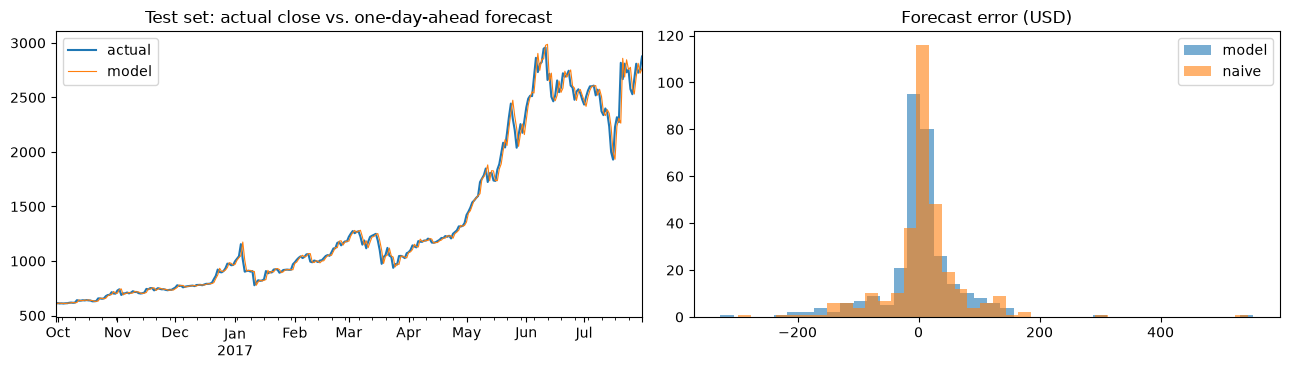

In [15]:
# Chosen model and both baselines on the same, never-seen test days.
last_close = X_test["close_lag_1"]
predictions = predict_price(final_pipeline, TARGET_KIND, X_test)
test_predictions = {BEST: predictions}
for name in BASELINES:
    pipeline, kind = candidates[name]
    fitted = fit_model(clone(pipeline), kind, X_train, y_train)
    test_predictions[name] = predict_price(fitted, kind, X_test)

test_table = pd.DataFrame({
    name: price_metrics(y_test, predicted, last_close)
    for name, predicted in test_predictions.items()
}).T
display(test_table.round(4))

test_metrics = {
    k: round(float(v), 4) for k, v in test_table.loc[BEST].items()
}
baseline_metrics = {
    k: round(float(v), 4) for k, v in test_table.loc[NAIVE].items()
    if not np.isnan(v)
}
BEATS_NAIVE = bool(test_metrics["rmse"] < baseline_metrics["rmse"])
print("Test days:", len(y_test))
print("Model RMSE / naive RMSE:",
      round(test_metrics["rmse"] / baseline_metrics["rmse"], 4))
print("Model MAE / naive MAE:",
      round(test_metrics["mae"] / baseline_metrics["mae"], 4))
print("Beats the naive forecast on test RMSE:", BEATS_NAIVE)
print("Share of up days in the test set (always-up direction rule):",
      round(float((y_test > last_close).mean()), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
y_test.plot(ax=axes[0], label="actual")
predictions.plot(ax=axes[0], label="model", lw=0.8)
axes[0].set_title("Test set: actual close vs. one-day-ahead forecast")
axes[0].set_xlabel("")
axes[0].legend()
axes[1].hist(y_test - predictions, bins=40, alpha=0.6, label="model")
axes[1].hist(y_test - last_close, bins=40, alpha=0.6, label="naive")
axes[1].set_title("Forecast error (USD)")
axes[1].legend()
plt.tight_layout()
plt.show()

dow__day_of_week_6     0.00013
dow__day_of_week_1     0.00024
dow__day_of_week_5     0.00035
dow__day_of_week_4     0.00053
dow__day_of_week_3     0.00114
dow__day_of_week_0     0.00176
dow__day_of_week_2     0.00460
num__return_lag_7      0.03823
num__return_std_30     0.05008
num__return_std_7      0.05160
num__return_lag_5      0.05421
num__return_lag_2      0.05506
num__return_lag_3      0.06201
num__return_lag_6      0.07407
num__return_mean_30    0.08637
num__return_lag_4      0.08872
num__gap_sma_30        0.09224
num__gap_sma_7         0.09761
num__return_lag_1      0.09867
num__return_mean_7     0.14237
Name: Feature importance, dtype: float64

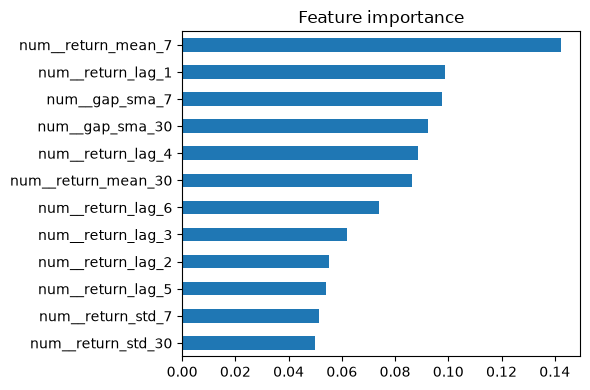

Predicted daily change %: mean 0.3091 | std 0.5045 | min -0.7532 | max 1.9619
Actual daily change %:    mean 0.5824 | std 3.7688 | min -14.3134 | max 23.9361
Correlation predicted vs. actual change: 0.0494


In [16]:
# What the model learned: coefficients or feature importance.
estimator = final_pipeline.named_steps["model"]
feature_names = final_pipeline.named_steps["prep"].get_feature_names_out()
if hasattr(estimator, "feature_importances_"):
    weights, title = estimator.feature_importances_, "Feature importance"
else:
    weights, title = estimator.coef_, "Coefficients (scaled inputs)"
importance = pd.Series(weights, index=feature_names).sort_values(key=abs)
display(importance.round(5).rename(title))
if hasattr(estimator, "intercept_"):
    print("Intercept:", round(float(estimator.intercept_), 6))
importance.tail(12).plot(kind="barh", figsize=(6, 4), title=title)
plt.tight_layout()
plt.show()

# How far the model moves away from "tomorrow = today".
predicted_change = (predictions / last_close - 1) * 100
actual_change = (y_test / last_close - 1) * 100
print("Predicted daily change %: mean", round(predicted_change.mean(), 4),
      "| std", round(predicted_change.std(), 4),
      "| min", round(predicted_change.min(), 4),
      "| max", round(predicted_change.max(), 4))
print("Actual daily change %:    mean", round(actual_change.mean(), 4),
      "| std", round(actual_change.std(), 4),
      "| min", round(actual_change.min(), 4),
      "| max", round(actual_change.max(), 4))
print("Correlation predicted vs. actual change:",
      round(float(np.corrcoef(predicted_change, actual_change)[0, 1]), 4))

In [17]:
# Error analysis: model against the naive forecast, day by day.
from scipy import stats as scipy_stats

errors = pd.DataFrame({
    "actual": y_test,
    "model": (y_test - predictions).abs(),
    "naive": (y_test - last_close).abs(),
})
errors["model_pct"] = errors["model"] / errors["actual"] * 100
errors["naive_pct"] = errors["naive"] / errors["actual"] * 100
by_quarter = errors.groupby(errors.index.to_period("Q")).agg(
    days=("actual", "size"),
    mean_close=("actual", "mean"),
    model_mae=("model", "mean"),
    naive_mae=("naive", "mean"),
    model_mape=("model_pct", "mean"),
    naive_mape=("naive_pct", "mean"),
)
display(by_quarter.round(3))
print("Days the model is closer than naive:",
      round(float((errors["model"] < errors["naive"]).mean()), 4))
# Paired test on the percentage errors (H0: same mean error).
difference = errors["naive_pct"] - errors["model_pct"]
t_stat, p_value = scipy_stats.ttest_1samp(difference, 0.0)
print("Mean (naive - model) absolute % error:", round(difference.mean(), 4),
      "| t =", round(float(t_stat), 3), "| p =", round(float(p_value), 4))
print("Largest model errors:")
display(
    errors.sort_values("model", ascending=False).head(5).round(2)
)

# Every candidate on the test set, for reference only (not used to choose).
reference = {}
for name, (pipeline, kind) in candidates.items():
    fitted = fit_model(clone(pipeline), kind, X_train, y_train)
    reference[name] = price_metrics(
        y_test, predict_price(fitted, kind, X_test), last_close
    )
display(pd.DataFrame(reference).T.sort_values("rmse").round(4))

,days,mean_close,model_mae,naive_mae,model_mape,naive_mape
date,,,,,,
2016Q3,1,609.740,3.420,4.050,0.561,0.664
2016Q4,92,732.721,9.011,9.077,1.190,1.194
2017Q1,90,1034.707,29.127,30.001,2.844,2.927
2017Q2,91,1912.552,57.596,59.694,2.729,2.838
2017Q3,31,2519.418,105.016,104.451,4.195,4.181


Days the model is closer than naive: 0.5869
Mean (naive - model) absolute % error: 0.0571 | t = 1.791 | p = 0.0743
Largest model errors:


,actual,model,naive,model_pct,naive_pct
date,,,,,
2017-07-20,2817.60,553.29,544.17,19.64,19.31
2017-06-12,2659.63,327.46,298.48,12.31,11.22
2017-07-17,2228.41,295.36,298.59,13.25,13.40
2017-07-15,1998.86,228.81,234.48,11.45,11.73
2017-06-14,2506.37,216.71,210.65,8.65,8.40


,rmse,mae,mape,r2,directional_accuracy
Drift (mean return),69.5680,39.6741,2.4702,0.9904,0.6382
Naive (tomorrow = today),69.7329,40.0305,2.4977,0.9903,NaN
Ridge on returns,70.7349,40.2087,2.5169,0.9901,0.5263
Random Forest on returns,71.3902,40.1641,2.4759,0.9899,0.5822
Gradient Boosting on returns,71.8776,40.8053,2.5356,0.9897,0.5625
Linear regression on price lags,73.1402,42.0994,2.6362,0.9894,0.4572
Random Forest on price lags,800.5735,472.0698,22.1689,-0.2743,0.4178


In [18]:
# Deployment model: same model and hyperparameters, refitted on ALL the days
# of the training file, then checked on the separate 7-day Kaggle file with
# one-day-ahead forecasts (each day uses the real closes up to the day
# before).
deploy_pipeline = fit_model(clone(final_pipeline), TARGET_KIND, X, y)

extended = pd.concat([df, kaggle_week], ignore_index=True)
assert (extended[DATE_COLUMN].diff().dropna().dt.days == 1).all()
week = make_dataset(extended).iloc[-len(kaggle_week):]
X_week, y_week = week.drop(columns=TARGET_COLUMN), week[TARGET_COLUMN]
week_model = predict_price(deploy_pipeline, TARGET_KIND, X_week)
week_table = pd.DataFrame({
    "actual": y_week,
    "naive": X_week["close_lag_1"],
    "model": week_model.round(2),
})
week_table["naive_error"] = week_table["actual"] - week_table["naive"]
week_table["model_error"] = week_table["actual"] - week_table["model"]
display(week_table.round(2))
week_scores = pd.DataFrame({
    BEST: price_metrics(y_week, week_model, X_week["close_lag_1"]),
    NAIVE: price_metrics(
        y_week, X_week["close_lag_1"], X_week["close_lag_1"]
    ),
}).T
display(week_scores.round(4))
kaggle_week_metrics = {
    "model": {
        k: round(float(v), 4) for k, v in week_scores.loc[BEST].items()
    },
    "naive": {
        k: round(float(v), 4) for k, v in week_scores.loc[NAIVE].items()
        if not np.isnan(v)
    },
}

,actual,naive,model,naive_error,model_error
date,,,,,
2017-08-01,2718.26,2875.34,2889.08,-157.08,-170.82
2017-08-02,2710.67,2718.26,2718.59,-7.59,-7.92
2017-08-03,2804.73,2710.67,2715.16,94.06,89.57
2017-08-04,2895.89,2804.73,2815.55,91.16,80.34
2017-08-05,3252.91,2895.89,2901.15,357.02,351.76
2017-08-06,3213.94,3252.91,3290.51,-38.97,-76.57
2017-08-07,3378.94,3213.94,3227.86,165.00,151.08


,rmse,mae,mape,r2,directional_accuracy
Random Forest on returns,167.3946,132.5809,4.3160,0.5785,0.5714
Naive (tomorrow = today),168.2244,130.1257,4.2331,0.5743,NaN


**Interpretation.** On the 305 test days the model has an **RMSE of 69.98 USD**, an MAE of 39.18 USD and a MAPE of 2.44 %. The naive forecast has an RMSE of **69.73 USD**, an MAE of 40.03 USD and a MAPE of 2.50 %. **The model does not beat the naive forecast on RMSE** (ratio 1.004); it is slightly better on MAE (ratio 0.979) and MAPE. Both differences are very small. The errors in USD are much larger than in cross-validation mainly because the test prices are several times higher; in percentage terms they are similar (MAPE 2.44 % on the test set against 2.28 % for the tuned model in cross-validation).

- **R2 = 0.990 is not evidence of skill.** The naive forecast gets the same 0.990: R2 on a price level only says that tomorrow's price is close to today's.
- **Is the small MAE advantage real?** The model is closer to the actual close than the naive forecast on 58.7 % of the days, and its absolute percentage error is on average 0.057 percentage points lower. A paired t-test on that difference gives t = 1.79 and p = 0.074, which is not significant at the 5 % level. This test compares absolute percentage errors, not the RMSE used as the selection criterion; no significance test was run on the RMSE difference, where the naive forecast is the one ahead (ratio 1.004). The honest reading is that, on this test set, the model is **not statistically distinguishable from the naive forecast**.
- **Directional accuracy:** the model gets the direction right on 62.5 % of the test days. This is not skill either: 63.6 % of the test days closed higher, so always answering "up" does at least as well (the drift baseline, which always predicts a rise, scores 63.8 %). The model's predicted change is positive on average (+0.31 %), in line with the positive mean return of the series.
- **The drift baseline has the lowest RMSE** (69.57 USD). This is consistent with the test period being a strongly rising market (the close goes from about 610 to 2875 USD); the same baseline would not help in a falling year such as 2014.

**What the model learned.** The predicted daily changes are very small: between -0.75 % and +1.96 %, with a standard deviation of 0.50 %, while the actual changes range from -14.3 % to +23.9 %, with a standard deviation of 3.77 %. The correlation between predicted and actual changes is 0.049. In practice, the model is "today's close plus a small adjustment". The most important features are the 7-day mean return (importance 0.14), the last return (0.10) and the distances to the 7- and 30-day moving averages (0.10 and 0.09). The importance is spread fairly evenly over the return features (from 0.04 to 0.14), with no dominant predictor. The day-of-week indicators have importances below 0.005: the Monday effect seen in the exploration did not become a useful feature.

**Error analysis:**
- **By period:** the percentage error is higher in the later, more volatile part of the test period, for the model and the naive forecast alike: the model's MAPE is 1.19 % in the last quarter of 2016, 2.84 % and 2.73 % in the first two quarters of 2017, and 4.20 % in July 2017. The model is marginally better than the naive forecast in every quarter up to June 2017 and marginally worse in July 2017.
- **Largest errors:** they occur on days of abrupt moves. On 2017-07-20 the price rose to 2817.60 USD and the model missed by 553 USD (19.6 %), the naive forecast by 544 USD; the other four largest errors are also in June and July 2017.
- **Other candidates on the test set (reference only, not used to choose):** the return models, before tuning, are between 70.7 and 71.9 USD and the linear model on price lags is at 73.1 USD, all slightly worse than the naive forecast. The Random Forest on price lags fails (RMSE 800.6 USD, R2 -0.27) because it cannot predict above the highest training price, as anticipated in section 4. The untuned Random Forest on returns gets 71.39 USD, so tuning also helped a little out of sample.

**Extra check on the 7-day Kaggle file.** The model was refitted with the same hyperparameters on all 1525 days and used to forecast 2017-08-01 to 2017-08-07 one day ahead. It gets an RMSE of 167.39 USD and an MAE of 132.58 USD (MAPE 4.32 %); the naive forecast gets 168.22 USD and 130.13 USD (MAPE 4.23 %). It is again a tie: slightly better on RMSE, slightly worse on MAE. The model got the direction right on 4 of the 7 days. Seven days are far too few to conclude anything; that week the price rose from 2718 to 3379 USD and included a jump of 357 USD in one day (2017-08-05) that neither forecast anticipated.

**Possible causes of error:** daily returns are close to unpredictable from past prices alone (the lag-1 autocorrelation in section 3 is near zero); the price is likely to react to news, regulation and other events that are not in the data; volatility changes over time; and the test period (a rising market that reaches prices far above any in the training period) is unlike most of the training period.

## Export for the backend

In [19]:
joblib.dump(deploy_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib")

# The backend forecasts from this history: the last closes of the data.
history_closes = df[TARGET_COLUMN].tolist()[-HISTORY_DAYS:]
last_date = df[DATE_COLUMN].iloc[-1]
forecast_date = last_date + pd.Timedelta(days=1)
default_features = pd.DataFrame(
    [build_features(history_closes, forecast_date)]
)
expected = round(
    float(
        predict_price(deploy_pipeline, TARGET_KIND, default_features).iloc[0]
    ),
    2,
)

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": "time_series",
    "target": "next-day close, USD",
    "target_kind": TARGET_KIND,
    "features": (
        RETURN_FEATURES if TARGET_KIND == "log_return" else LEVEL_FEATURES
    ),
    "feature_columns": X.columns.tolist(),
    "history_days": HISTORY_DAYS,
    "test_metrics": test_metrics,
    "baseline_test_metrics": baseline_metrics,
    "beats_naive_on_test": BEATS_NAIVE,
    "test_period": [str(X_test.index.min().date()),
                    str(X_test.index.max().date())],
    "kaggle_week_metrics": kaggle_week_metrics,
    "trained_on": [str(X.index.min().date()), str(X.index.max().date())],
    # The last close of the data: with it the backend forecasts the day
    # after the data ends; another value means "the user's latest price".
    "default_input": {"last_price": history_closes[-1]},
    "history": {
        "last_date": str(last_date.date()),
        "forecast_date": str(forecast_date.date()),
        "closes": history_closes,
    },
    "expected_default_prediction": expected,
    "sklearn_version": sklearn.__version__,
}
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print(f"Saved artifacts/{MODEL_NAME}.joblib and {meta_path.name}")
print("Last close:", history_closes[-1], "on", last_date.date())
print("Forecast for", forecast_date.date(), ":", expected, "USD")
print("Actual close that day (7-day file):",
      kaggle_week[TARGET_COLUMN].iloc[0])
print(json.dumps({k: v for k, v in meta.items() if k != "history"},
                 indent=2, default=str))

Saved artifacts/bitcoin.joblib and bitcoin.meta.json
Last close: 2875.34 on 2017-07-31
Forecast for 2017-08-01 : 2889.08 USD
Actual close that day (7-day file): 2718.26
{
  "model": "Random Forest on returns",
  "hyperparameters": {
    "max_depth": 6,
    "max_features": 0.33,
    "min_samples_leaf": 50
  },
  "task": "time_series",
  "target": "next-day close, USD",
  "target_kind": "log_return",
  "features": [
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "return_lag_4",
    "return_lag_5",
    "return_lag_6",
    "return_lag_7",
    "return_mean_7",
    "return_std_7",
    "gap_sma_7",
    "return_mean_30",
    "return_std_30",
    "gap_sma_30",
    "day_of_week"
  ],
  "feature_columns": [
    "close_lag_1",
    "close_lag_2",
    "close_lag_3",
    "close_lag_4",
    "close_lag_5",
    "close_lag_6",
    "close_lag_7",
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "return_lag_4",
    "return_lag_5",
    "return_lag_6",
    "return_lag_7",
    

## 6. Conclusion

The model forecasts tomorrow's Bitcoin close with a typical error of **2.4 %** (test MAE 39 USD, RMSE 70 USD), and **it does not beat the naive forecast "tomorrow = today"** (RMSE 69.73 USD): the difference between the two is not statistically significant on the test set (a paired t-test on the absolute percentage errors, not on the RMSE used as the selection criterion), and the extra week is again a tie. The naive forecast was already ahead of every candidate in cross-validation, before the test set was touched. This result is consistent with the efficient-market hypothesis (Fama, 1970), and it is reported as it is: the model was chosen and tuned on the training days only, not on the test set. What the project does establish is (1) a sound way to frame the problem, modelling returns instead of the price level, without which a tree model fails completely (test RMSE 800 USD); (2) a chronological evaluation with no leakage; and (3) a realistic size for the uncertainty of a next-day forecast.

The Random Forest on returns is kept and served because it was the best trained candidate in cross-validation and behaves conservatively: on the test set its forecast was always today's close plus a small correction (between -0.75 % and +1.96 %). The exported model is refitted on all 1525 days (train + test) after the evaluation, so the reported test metrics belong to the train-only fit. For the user, the answer should be read as "about the same as today, give or take 2 to 3 %", never as a trading signal.

**Limitations:**
- No demonstrated advantage over the naive forecast.
- The data ends on **2017-07-31**: the served forecast is for 2017-08-01, not a live price, and JarvisTEC says so. A user can supply a recent price, but the model still applies patterns learned from 2013-2017.
- Only past closing prices are used; volume, news, sentiment and other markets are ignored.
- The model gives a single number, although the main feature of this series is how much its volatility changes.
- A single asset and a single chronological split; the test period is one rising market.

**Future improvements:**
- Forecast the **volatility** (the size of the move), which the exploration suggests is more predictable than the direction, and report a range instead of a single price.
- Add external information: traded volume, on-chain activity, sentiment or search trends.
- Evaluate with a rolling origin over several years and refit the model as new days arrive.
- Connect a live price source so that the forecast refers to the real "tomorrow".
- Compare with classical time-series models (ARIMA, GARCH) and with other machine-learning approaches such as those studied by McNally et al. (2018).

**Voice commands for this model:** *"JarvisTEC, bitcoin price"*, *"JarvisTEC, price of bitcoin"*, *"JarvisTEC, bitcoin price tomorrow"*, *"JarvisTEC, bit coin"*, *"JarvisTEC, bitcoin"*

### References

- Nakamoto, S. (2008). *Bitcoin: A peer-to-peer electronic cash system*. https://bitcoin.org/bitcoin.pdf
- McNally, S., Roche, J., & Caton, S. (2018). Predicting the price of Bitcoin using machine learning. In *2018 26th Euromicro International Conference on Parallel, Distributed and Network-based Processing (PDP)* (pp. 339-343). IEEE. https://doi.org/10.1109/PDP2018.2018.00060
- Fama, E. F. (1970). Efficient capital markets: A review of theory and empirical work. *The Journal of Finance, 25*(2), 383-417. https://doi.org/10.2307/2325486
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.